In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('athlete_events.csv')
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [18]:
"""
New columns:
-Athlete_Medal_Count: Count of medals by athlete (ID needed because of possibility of duplicate names)
-Athlete_OneGame_Medal_Count: Count of medals by athlete for a single Games

-Gold_Medal_Flag: Indicates Gold Medal or not
-Silver_Medal_Flag: Indicates Silver Medal or not
-Bronze_Medal_Flag: Indicates Bronze Medal or not
"""
df['Athlete_Medal_Count'] = df.groupby(['ID','Name'])['Medal'].transform('count')
df['Athlete_OneGame_Medal_Count'] = df.groupby(['ID','Name','Games'])['Medal'].transform('count')

df['Gold_Medal_Flag'] = df['Medal'].map({'Gold': 'Gold'})
df['Athlete_OneGame_GoldMedal_Count'] = df.groupby(['ID','Name','Games'])['Gold_Medal_Flag'].transform('count')
#df['Silver_Medal_Flag'] = df['Medal'].map({'Silver': 1})
#df['Bronze_Medal_Flag'] = df['Medal'].map({'Bronze': 1})

In [19]:
df.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,Athlete_Medal_Count,Athlete_OneGame_Medal_Count,Gold_Medal_Flag,Athlete_OneGame_GoldMedal_Count
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,0,0,NaN,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,0,0,NaN,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,0,0,NaN,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,1,1,Gold,1
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,0,0,NaN,0


In [5]:
athlete_medal_counts = df.loc[:, ['Name', 'Sex', 'Season', 'Athlete_Medal_Count']].drop_duplicates().sort_values(by='Athlete_Medal_Count')
#removing sport to account for multi-sport athletes
#adding sex for medals by gender

In [6]:
#Check if athletes with same name are aggregated (they are not, thankfully)
athlete_medal_counts[athlete_medal_counts.Name=='Takashi Ono']

,Name,Sex,Season,Athlete_Medal_Count
177440,Takashi Ono,M,Summer,0
177408,Takashi Ono,M,Summer,13


In [7]:
athlete_medal_counts[athlete_medal_counts.Athlete_Medal_Count>0]

,Name,Sex,Season,Athlete_Medal_Count
100365,"Anthony Francis ""Fran"" Huck",M,Winter,1
23339,Viktor Nikolayevich Blinov,M,Winter,1
23366,Alfred Bloch,M,Summer,1
137567,Yuliya Aleksandrovna Levina,F,Summer,1
137560,John Gustaf Hjalmar Levin,M,Summer,1
...,...,...,...,...
22698,Ole Einar Bjrndalen,M,Winter,13
217312,Borys Anfiyanovych Shakhlin,M,Summer,13
7510,Nikolay Yefimovich Andrianov,M,Summer,15
133184,Larysa Semenivna Latynina (Diriy-),F,Summer,18


In [8]:
summer_athlete_medal_counts = athlete_medal_counts[athlete_medal_counts.Season=='Summer']
winter_athlete_medal_counts = athlete_medal_counts[athlete_medal_counts.Season=='Winter']

In [9]:
summer_athlete_medal_counts

,Name,Sex,Season,Athlete_Medal_Count
0,A Dijiang,M,Summer,0
169043,Douglas Mortimer Lewes Neame,M,Summer,0
169030,"Charles R. ""Jack"" Neale",M,Summer,0
169023,Ian G. Neale,M,Summer,0
169021,Shay Neal,M,Summer,0
...,...,...,...,...
177408,Takashi Ono,M,Summer,13
217312,Borys Anfiyanovych Shakhlin,M,Summer,13
7510,Nikolay Yefimovich Andrianov,M,Summer,15
133184,Larysa Semenivna Latynina (Diriy-),F,Summer,18


In [10]:
winter_athlete_medal_counts

,Name,Sex,Season,Athlete_Medal_Count
169022,"William ""Bill"" Neale",M,Winter,0
169009,Paul Neagu,M,Winter,0
169002,Andreas Neagu,M,Winter,0
169000,Virgil Neagoe,M,Winter,0
169114,Ayumu Nedefuji,M,Winter,0
...,...,...,...,...
56098,"Ursula ""Uschi"" Disl",F,Winter,9
22666,Marit Bjrgen,F,Winter,10
223209,Raisa Petrovna Smetanina,F,Winter,10
18375,Stefania Belmondo,F,Winter,10


In [11]:
male_medal_counts = athlete_medal_counts[athlete_medal_counts.Sex=='M']
female_medal_counts = athlete_medal_counts[athlete_medal_counts.Sex=='F']

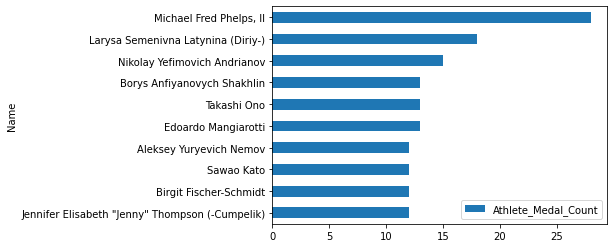

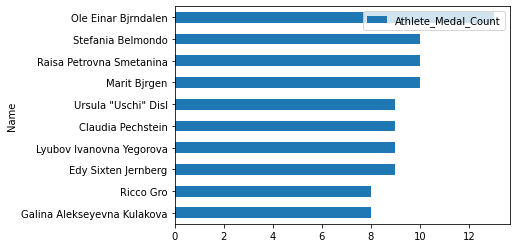

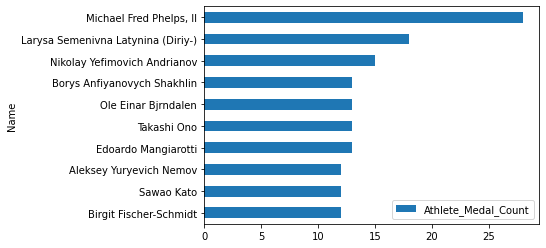

In [13]:
summer_top10 = summer_athlete_medal_counts.tail(10).plot.barh(x='Name', y='Athlete_Medal_Count')
winter_top10 = winter_athlete_medal_counts.tail(10).plot.barh(x='Name', y='Athlete_Medal_Count')
overall_top10 = athlete_medal_counts.tail(10).plot.barh(x='Name', y='Athlete_Medal_Count')

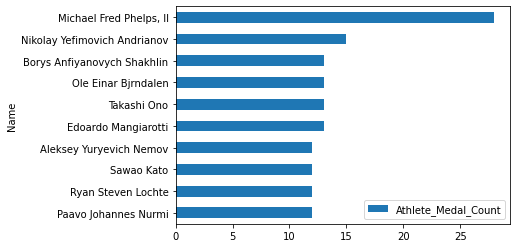

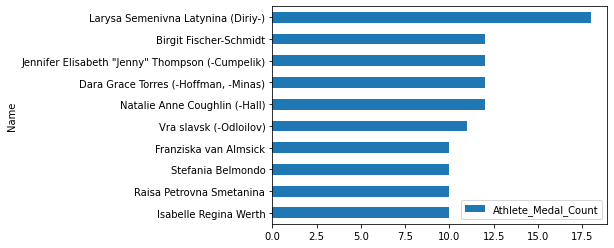

In [15]:
male_top10 = male_medal_counts.tail(10).plot.barh(x='Name', y='Athlete_Medal_Count')
female_top10 = female_medal_counts.tail(10).plot.barh(x='Name', y='Athlete_Medal_Count')

In [17]:
df[df.Athlete_OneGame_Medal_Count>5].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'Athlete_OneGame_Medal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_Medal_Count', ascending=False)

,Name,Sex,Sport,Games,Athlete_OneGame_Medal_Count
187888,"Michael Fred Phelps, II",M,Swimming,2004 Summer,8
56199,Aleksandr Nikolayevich Dityatin,M,Gymnastics,1980 Summer,8
187896,"Michael Fred Phelps, II",M,Swimming,2008 Summer,8
7518,Nikolay Yefimovich Andrianov,M,Gymnastics,1976 Summer,7
217320,Borys Anfiyanovych Shakhlin,M,Gymnastics,1960 Summer,7
22090,"Matthew Nicholas ""Matt"" Biondi",M,Swimming,1988 Summer,7
135507,"Willis Augustus Lee, Jr.",M,Shooting,1920 Summer,7
98812,Mariya Kindrativna Horokhovska,F,Gymnastics,1952 Summer,7
226662,Mark Andrew Spitz,M,Swimming,1972 Summer,7
226726,Lloyd Spencer Spooner,M,Shooting,1920 Summer,7


In [20]:
df[df.Athlete_OneGame_GoldMedal_Count>4].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'Athlete_OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_GoldMedal_Count', ascending=False)

,Name,Sex,Sport,Games,Athlete_OneGame_GoldMedal_Count
187896,"Michael Fred Phelps, II",M,Swimming,2008 Summer,8
226662,Mark Andrew Spitz,M,Swimming,1972 Summer,7
179153,Kristin Otto,F,Swimming,1988 Summer,6
187888,"Michael Fred Phelps, II",M,Swimming,2004 Summer,6
217832,Vitaly Venediktovich Shcherbo,M,Gymnastics,1992 Summer,6
22090,"Matthew Nicholas ""Matt"" Biondi",M,Swimming,1988 Summer,5
93166,Anton Heida,M,Gymnastics,1904 Summer,5
93199,Eric Arthur Heiden,M,Speed Skating,1980 Winter,5
135507,"Willis Augustus Lee, Jr.",M,Shooting,1920 Summer,5
167263,Nedo Nadi,M,Fencing,1920 Summer,5


In [21]:
df[(df.Sex=='F') & (df.Athlete_OneGame_GoldMedal_Count>3)].loc[:, ['Name', 'Sex', 'Sport', 'Games', 'Athlete_OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_GoldMedal_Count', ascending=False)

,Name,Sex,Sport,Games,Athlete_OneGame_GoldMedal_Count
179153,Kristin Otto,F,Swimming,1988 Summer,6
21758,Simone Arianne Biles,F,Gymnastics,2016 Summer,4
23132,"Francina Elsje ""Fanny"" Blankers-Koen",F,Athletics,1948 Summer,4
36625,Vra slavsk (-Odloilov),F,Gymnastics,1968 Summer,4
63527,"Kornelia Ender (-Matthes, -Grummt)",F,Swimming,1976 Summer,4
72307,"Melissa Jeanette ""Missy"" Franklin",F,Swimming,2012 Summer,4
115446,gnes Keleti-Srkny (Klein),F,Gymnastics,1956 Summer,4
133184,Larysa Semenivna Latynina (Diriy-),F,Gymnastics,1956 Summer,4
134632,"Kathleen Genevieve ""Katie"" Ledecky",F,Swimming,2016 Summer,4
222312,Lidiya Pavlovna Skoblikova (-Polozkova),F,Speed Skating,1964 Winter,4


In [22]:
df[(df.Sex=='M') & (df.Athlete_OneGame_GoldMedal_Count>3)].loc[:, ['Name', 'Sex', 'Games', 'Athlete_OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by='Athlete_OneGame_GoldMedal_Count', ascending=False)
#removing sport b/c of multi-sport athletes at one games

,Name,Sex,Games,Athlete_OneGame_GoldMedal_Count
187896,"Michael Fred Phelps, II",M,2008 Summer,8
226662,Mark Andrew Spitz,M,1972 Summer,7
217832,Vitaly Venediktovich Shcherbo,M,1992 Summer,6
187888,"Michael Fred Phelps, II",M,2004 Summer,6
187911,"Michael Fred Phelps, II",M,2016 Summer,5
167263,Nedo Nadi,M,1920 Summer,5
135507,"Willis Augustus Lee, Jr.",M,1920 Summer,5
173963,Paavo Johannes Nurmi,M,1924 Summer,5
93199,Eric Arthur Heiden,M,1980 Winter,5
93166,Anton Heida,M,1904 Summer,5


In [31]:
#next: do stacked plot of gold medal count and overall medal count
stacked_medal_counts = df.loc[:, ['Name', 'Athlete_OneGame_Medal_Count', 'Athlete_OneGame_GoldMedal_Count']].drop_duplicates().sort_values(by=['Athlete_OneGame_GoldMedal_Count', 'Athlete_OneGame_Medal_Count'], ascending=False)
stacked_medal_counts[stacked_medal_counts.Athlete_OneGame_Medal_Count>5]

,Name,Athlete_OneGame_Medal_Count,Athlete_OneGame_GoldMedal_Count
187896,"Michael Fred Phelps, II",8,8
226662,Mark Andrew Spitz,7,7
187888,"Michael Fred Phelps, II",8,6
179153,Kristin Otto,6,6
217832,Vitaly Venediktovich Shcherbo,6,6
22090,"Matthew Nicholas ""Matt"" Biondi",7,5
135507,"Willis Augustus Lee, Jr.",7,5
93166,Anton Heida,6,5
187911,"Michael Fred Phelps, II",6,5
7518,Nikolay Yefimovich Andrianov,7,4


In [37]:
import matplotlib.pyplot as plt
%matplotlib inline

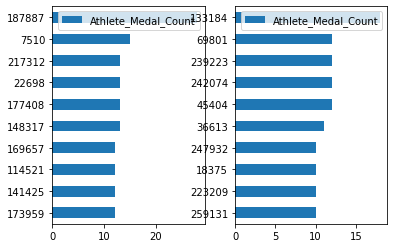

In [39]:
male_top_10_medals = male_medal_counts.tail(10)
female_top_10_medals = female_medal_counts.tail(10)

fig, axes = plt.subplots(nrows=1, ncols=2)
male_top_10_medals[["Name","Athlete_Medal_Count"]].plot(ax=axes[0], kind='barh')
female_top_10_medals[["Name", "Athlete_Medal_Count"]].plot(ax=axes[1], kind='barh');